In [2]:
# Zomato Food Delivery Prediction - Random Forest Model
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier


In [3]:
# Load dataset
data = pd.read_csv("Zomato Dataset.csv")
df = pd.DataFrame(data)
print(df.head())
print(df.info())
print(df.describe())
print(df.isnull().sum())


       ID Delivery_person_ID  Delivery_person_Age  Delivery_person_Ratings  \
0  0xcdcd      DEHRES17DEL01                 36.0                      4.2   
1  0xd987      KOCRES16DEL01                 21.0                      4.7   
2  0x2784     PUNERES13DEL03                 23.0                      4.7   
3  0xc8b6     LUDHRES15DEL02                 34.0                      4.3   
4  0xdb64      KNPRES14DEL02                 24.0                      4.7   

   Restaurant_latitude  Restaurant_longitude  Delivery_location_latitude  \
0            30.327968             78.046106                   30.397968   
1            10.003064             76.307589                   10.043064   
2            18.562450             73.916619                   18.652450   
3            30.899584             75.809346                   30.919584   
4            26.463504             80.372929                   26.593504   

   Delivery_location_longitude  Order_Date Time_Orderd Time_Order_picked  

In [4]:
# Select available input features
possible_features = [
    "distance",
    "traffic",
    "weather",
    "Vehicle_condition",
    "Road_traffic_density",
    "Type_of_vehicle"
]

features = [
    col for col in possible_features
    if col in df.columns
]

if not features:
    raise ValueError(
        "No matching feature columns found. "
        "Check df.columns and update possible_features."
    )


In [5]:
X = df[features]

# Create target column 'is_delayed' based on 'Time_taken (min)'
# If a delivery takes more than 30 minutes, we classify it as delayed (1), otherwise not delayed (0)
df["is_delayed"] = (df["Time_taken (min)"] > 30).astype(int)
y = df["is_delayed"]

In [6]:
# Identify numerical and categorical columns
numeric_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Prepare numerical data
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Prepare categorical data
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [7]:
# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])

In [8]:
# Build model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])


In [9]:
# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [10]:
# Train model
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Evaluate accuracy
accuracy = accuracy_score(y_test, y_pred)

In [12]:
columns = pd.DataFrame({'Input Features': y_test.values, 'Predicted Features': y_pred})
columns['Actual Status'] = columns['Input Features'].map({0: 'Not Delayed', 1: 'Delayed'})
columns['Predicted Status'] = columns['Predicted Features'].map({0: 'Not Delayed', 1: 'Delayed'})
print(columns)

      Input Features  Predicted Features Actual Status Predicted Status
0                  1                   0       Delayed      Not Delayed
1                  1                   1       Delayed          Delayed
2                  0                   0   Not Delayed      Not Delayed
3                  0                   0   Not Delayed      Not Delayed
4                  1                   0       Delayed      Not Delayed
...              ...                 ...           ...              ...
9112               0                   0   Not Delayed      Not Delayed
9113               0                   0   Not Delayed      Not Delayed
9114               0                   0   Not Delayed      Not Delayed
9115               0                   0   Not Delayed      Not Delayed
9116               0                   0   Not Delayed      Not Delayed

[9117 rows x 4 columns]


In [13]:
print(f"\nModel Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Model Accuracy: 70.22%

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.70      0.77      6397
           1       0.50      0.72      0.59      2720

    accuracy                           0.70      9117
   macro avg       0.68      0.71      0.68      9117
weighted avg       0.75      0.70      0.71      9117



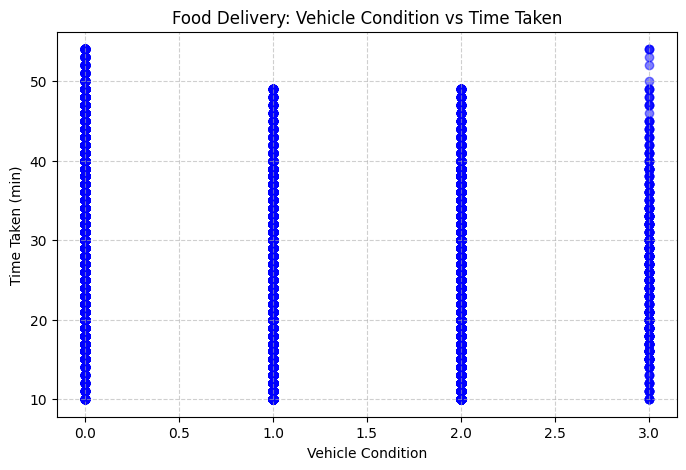

In [14]:
import matplotlib.pyplot as plt

# Let's plot 'Vehicle_condition' against 'is_delayed' or 'Time_taken (min)'
# Since X has multiple columns, we will select 'Vehicle_condition' for visualization
plt.figure(figsize=(8, 5))
plt.scatter(df["Vehicle_condition"], df["Time_taken (min)"], alpha=0.5, color='blue')
plt.xlabel("Vehicle Condition")
plt.ylabel("Time Taken (min)")
plt.title("Food Delivery: Vehicle Condition vs Time Taken")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()